# Sesiunea 9 - Gradient Boosting si SVM

## Pregatire (ruleaza o data)

Azi lucram cu doua seturi de date diferite:
- **Titanic**, pentru partea de Gradient Boosting / XGBoost (clasificare: a supravietuit sau nu)
- **Digits** (cifre scrise de mana, 8x8 pixeli) si doua seturi jucarie 2D, pentru partea de SVM

Mergem pas cu pas: intuitie, apoi un scenariu concret ("modelul tau face X, ce faci?"), apoi voi va jucati cu parametrii.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.datasets import load_digits, make_blobs, make_circles
from xgboost import XGBClassifier
plt.rcParams['figure.figsize'] = (8, 4.5)

df = pd.read_csv('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv')
df['SexNum'] = df['Sex'].map({'female': 0, 'male': 1})
FEATURES = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'SexNum']
X, y = df[FEATURES], df['Survived']

# Testul final ramane separat de experimentele de la curs.
X_dev_raw, X_holdout, y_dev, y_holdout = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y)
X_train_raw, X_valid_raw, y_train, y_valid = train_test_split(
    X_dev_raw, y_dev, test_size=0.25, random_state=1, stratify=y_dev)

imputer = SimpleImputer(strategy='median').set_output(transform='pandas')
X_train = imputer.fit_transform(X_train_raw)
X_valid = imputer.transform(X_valid_raw)
print('Train / validare / test final:', len(X_train), len(X_valid), len(X_holdout))

display(df[FEATURES + ['Survived']].head())

Train / validare / test final: 534 178 179


,Pclass,Age,SibSp,Parch,Fare,SexNum,Survived
0,3,22.0,1,0,7.2500,1,0
1,1,38.0,1,0,71.2833,0,1
2,3,26.0,0,0,7.9250,0,1
3,1,35.0,1,0,53.1000,0,1
4,3,35.0,0,0,8.0500,1,0


Folosim validarea pentru experimente. Testul final se deschide o singura data, dupa alegerea modelului si a pragului. Mediana se invata numai din train. Pentru cautarile cu cross-validation punem imputarea in pipeline, separat in fiecare fold.

---
# Partea 1 · Gradient Boosting & XGBoost 🌳➡️🌳➡️🌳

In [21]:
tree = DecisionTreeClassifier(max_depth=4, random_state=0).fit(X_train, y_train)
boosted = XGBClassifier(n_estimators=100, max_depth=3,
                         eval_metric="logloss", random_state=0).fit(X_train, y_train)

print(f"Un singur arbore (max_depth=4):     acuratete validare = {accuracy_score(y_valid, tree.predict(X_valid)):.3f}")
print(f"XGBoost (100 arbori mici, secvential): acuratete validare = {accuracy_score(y_valid, boosted.predict(X_valid)):.3f}")

Un singur arbore (max_depth=4):     acuratete validare = 0.781
XGBoost (100 arbori mici, secvential): acuratete validare = 0.809


Boosting adauga arbori succesivi care reduc erorile ansamblului. Castigul fata de un singur arbore se verifica pe validare; nu este garantat pentru orice configuratie.

## 2 · Scenariul 1: modelul tau "invata pe de rost" datele 🚨

Hai sa provocam intentionat o problema, ca sa o recunoasteti data viitoare cand apare singura. Antrenam un XGBoost mult prea complex: multi arbori, foarte adanci, care invata foarte agresiv.

In [22]:
overfit_model = XGBClassifier(n_estimators=500, max_depth=12,
                               eval_metric="logloss", random_state=0).fit(X_train, y_train)

train_acc = accuracy_score(y_train, overfit_model.predict(X_train))
test_acc = accuracy_score(y_valid, overfit_model.predict(X_valid))
print(f"train = {train_acc:.3f}")
print(f"validare  = {test_acc:.3f}")
print(f"diferenta (gap) = {train_acc - test_acc:.3f}")

train = 0.991
validare  = 0.787
diferenta (gap) = 0.204


**Intrebare** - Uitati-va la cele trei numere de mai sus. Ce s-a intamplat, si ce ati incerca sa schimbati?

## 3 · `learning_rate` si `n_estimators`: doua butoane care lucreaza impreuna 📈

Pana acum ati schimbat adancimea arborilor. Acum investigati cum se leaga viteza de invatare de numarul de arbori. Comparati configuratiile `(learning_rate=0.1, n_estimators=100)` si `(learning_rate=0.03, n_estimators=300)`, pastrand `max_depth=3`.

Pentru fiecare configuratie, afisati accuracy pe train si validare, apoi reprezentati pe acelasi grafic evolutia scorului de validare in functie de numarul de arbori folosind `evals_result_`. Ce compromis observati intre invatarea rapida si invatarea lenta?

In [23]:
# Completeaza rezolvarea aici.
# Indiciu: foloseste model.evals_result()['validation_0']['merror'] sau ['logloss']
# pentru a compara evolutia pe validare.

Compara configuratiile la aceeasi complexitate finala. Un `learning_rate` mai mic poate avea nevoie de mai multi arbori pentru a ajunge la un scor bun, dar poate invata mai gradual. Urmariti si momentul in care scorul de validare nu mai creste.

**Exercitiul 1.1 - Parametru cunoscut: `max_depth`**

Antreneaza doua modele XGBoost cu `max_depth=2`, respectiv `max_depth=8`, ambele cu `n_estimators=150` si `random_state=0`. Afiseaza accuracy pe train si validare si macro F1 pe validare. Care generalizeaza mai bine? Sustine raspunsul cu scoruri.

In [24]:
# Completeaza rezolvarea aici.

**Raspuns si justificare:**

...

## 5. Exercitiu independent - Controleaza un arbore de decizie

Foloseste `GridSearchCV` pentru `DecisionTreeClassifier`.

1. Cauta `max_depth` in `[2, 4, 8]` si `min_samples_leaf` in `[1, 5, 15]`. Acesta din urma cere un numar minim de exemple in fiecare frunza.
2. Pune `SimpleImputer(strategy="median")` in pipeline si foloseste datele brute de train.
3. Foloseste 5 folduri stratificate si `scoring="f1_macro"`.
4. Afiseaza configuratia castigatoare, media si deviatia scorurilor CV, apoi accuracy si macro F1 pe validare.
5. De ce nu alegem parametrii dupa testul final?

In [25]:
# Completeaza rezolvarea aici.

**Raspuns si justificare:**

...

---
# Partea 2 · Support Vector Machines 📐

## 6 · Vedem marja cu ochii nostri 👀

Inainte sa mergem pe date reale, construim un exemplu jucarie in 2D, exact ca pe slide, dar cu un SVM antrenat de-adevaratelea. Liniile punctate sunt marginile "strazii", iar punctele incercuite cu galben sunt vectorii suport, singurele care conteaza pentru pozitia granitei.

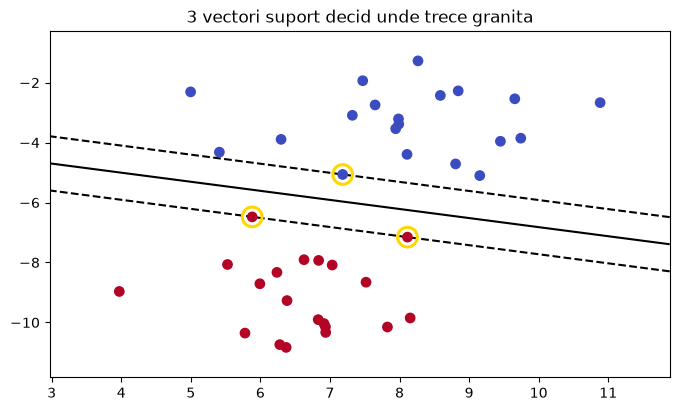

In [40]:
Xt, yt = make_blobs(n_samples=40, centers=2, cluster_std=1.15, random_state=6)
clf_margin = SVC(kernel="linear", C=1000).fit(Xt, yt)

xx, yy = np.meshgrid(np.linspace(Xt[:,0].min()-1, Xt[:,0].max()+1, 300),
                      np.linspace(Xt[:,1].min()-1, Xt[:,1].max()+1, 300))
Z = clf_margin.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.scatter(Xt[:,0], Xt[:,1], c=yt, cmap="coolwarm", s=45, zorder=3)
plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
plt.scatter(clf_margin.support_vectors_[:,0], clf_margin.support_vectors_[:,1],
            s=200, facecolors="none", edgecolors="gold", linewidths=2.2, zorder=4)
plt.title(f"{len(clf_margin.support_vectors_)} vectori suport decid unde trece granita")
plt.show()

**Scenariul 2: ce se intampla daca schimbam `C`?**

`C` controleaza cat de strict e SVM cu greselile: `C` mare = granita stricta (risc de overfitting), `C` mic = granita mai tolveranta, cu marja mai lata.

In [27]:
for C in [0.01, 1, 100]:
    m = SVC(kernel="linear", C=C).fit(Xt, yt)
    print(f"C={C:<7} -> {len(m.support_vectors_)} vectori suport, acuratete pe train = {m.score(Xt, yt):.2f}")

C=0.01    -> 18 vectori suport, acuratete pe train = 1.00
C=1       -> 3 vectori suport, acuratete pe train = 1.00
C=100     -> 3 vectori suport, acuratete pe train = 1.00


Cu `C` mic, SVM accepta mai multi vectori suport (o marja mai lata, mai toleranta). Cu `C` mare, marja se ingusteaza si modelul se lipeste mai tare de datele de antrenare, exact ca `max_depth` mare la XGBoost: mai multa "incredere" in datele vazute, mai mult risc de overfitting.

## 7 · Cand o linie dreapta nu e de-ajuns 📐

Reproducem exact experimentul cu cercuri concentrice: o clasa in interior, una in exterior. Comparam kernelul liniar cu `rbf`.

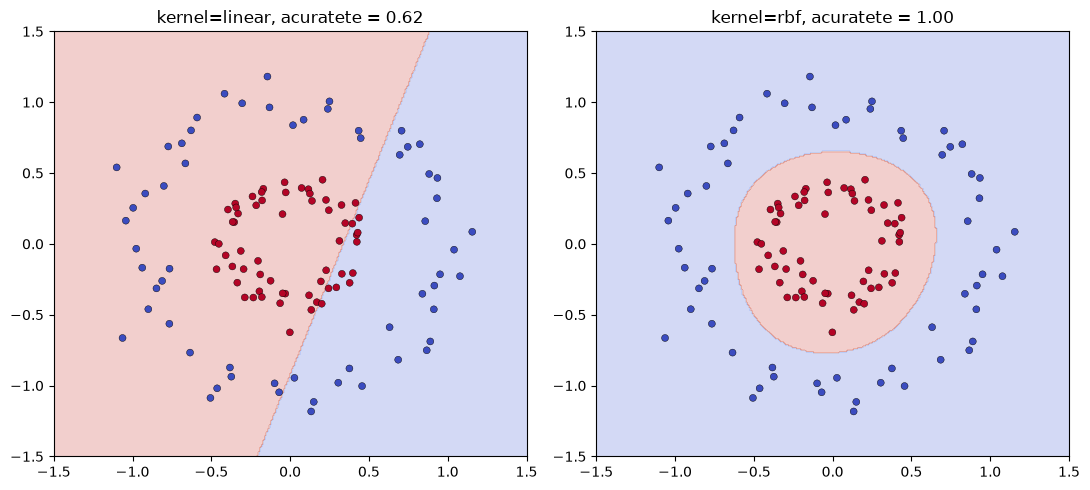

In [28]:
Xc, yc_ = make_circles(n_samples=120, factor=0.4, noise=0.08, random_state=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, kernel in zip(axes, ["linear", "rbf"]):
    m = SVC(kernel=kernel, C=5, gamma="scale").fit(Xc, yc_)
    xx, yy = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-1.5, 1.5, 300))
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
    ax.scatter(Xc[:,0], Xc[:,1], c=yc_, cmap="coolwarm", s=25, edgecolor="k", linewidth=0.3)
    ax.set_title(f"kernel={kernel}, acuratete = {m.score(Xc, yc_):.2f}")
plt.tight_layout(); plt.show()

Kernelul liniar nu are cum sa desparta un cerc de altul cu o linie dreapta. `rbf` gaseste imediat granita curba potrivita, fara sa transformam noi manual coordonatele.

## 8 · Acum pe date reale: cifre scrise de mana ✍️

Fiecare cifra e o imagine de 8x8 pixeli (64 de valori de gri). Vrem sa recunoastem automat cifra 0-9.

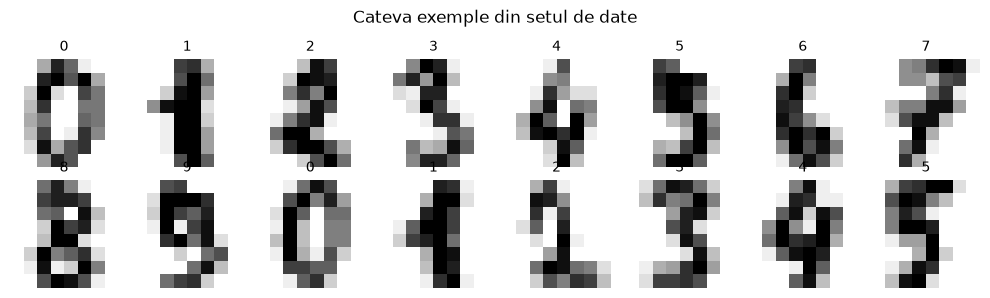

gata: 1437 train / 360 validare - 64 pixeli/imagine


In [29]:
digits = load_digits()
Xd, yd = digits.data, digits.target
Xd_train, Xd_valid, yd_train, yd_valid = train_test_split(Xd, yd, test_size=0.2, random_state=0, stratify=yd)

fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for ax, img, label in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap="gray_r"); ax.set_title(str(label), fontsize=10); ax.axis("off")
plt.suptitle("Cateva exemple din setul de date")
plt.tight_layout(); plt.show()
print("gata:", Xd_train.shape[0], "train /", Xd_valid.shape[0], "validare", "-", Xd.shape[1], "pixeli/imagine")

**Intrebare** - Pe baza a ce ati vazut la cercurile concentrice, ce va asteptati: `linear` sau `rbf` sa mearga mai bine pe cifre scrise de mana? De ce?

In [30]:
for kernel in ["linear", "rbf"]:
    svc = SVC(kernel=kernel, random_state=0).fit(Xd_train, yd_train)
    acc = accuracy_score(yd_valid, svc.predict(Xd_valid))
    print(f"kernel={kernel:7s} -> acuratete validare = {acc:.3f}")

kernel=linear  -> acuratete validare = 0.972
kernel=rbf     -> acuratete validare = 0.983


Observati ca SVM nu are nevoie de mii de exemple ca sa mearga bine, aici avem doar ~1400 de imagini in train.

**Exercitiul 8 - SVM RBF: joaca-te cu `C` si `gamma`**

Construieste un pipeline cu `StandardScaler` si `SVC(kernel="rbf")`. Testeaza cateva perechi de valori pentru `C` si `gamma`, de exemplu `(1, "scale")`, `(10, 0.01)`, `(0.1, 0.001)` si `(100, 0.1)`.

Afiseaza macro F1 pe validare pentru fiecare pereche. Alege configuratia cu cel mai bun scor, apoi afiseaza matricea de confuzie si gaseste perechea de cifre cu cele mai multe confuzii in ambele sensuri cumulate.

In [31]:
# Completeaza rezolvarea aici.

**Intrebari pentru discutie:**

1. De ce scalerul trebuie sa fie in pipeline, nu antrenat inainte de cross-validation?
2. Putem compara direct scorul SVM pe Digits cu XGBoost pe Titanic pentru a decide ce algoritm e mai bun?

# Tema integratoare - Ce model ai alege pentru Titanic?

Revii la acelasi tabel, dar folosesti doar XGBoost si SVM RBF, algoritmii discutati in aceasta sesiune. Poti genera cod cu un asistent AI, dar verifici fiecare pas si formulezi personal concluziile. Lucram cu `Survived` ca tinta, nu simulam o decizie reala de salvare.

Pastreaza spliturile de la inceput. Train-ul este pentru antrenare, validarea pentru alegerea modelului si pragului, iar `X_holdout` ramane neatins pana la o eventuala verificare finala. Titanic a fost deja explorat la curs, deci acesta este un exercitiu de metoda.

### Pasul 1 - Defineste problema

Ce tip de problema este? Ce s-ar schimba daca tinta ar fi `Fare`? Unde se potrivesc regresia liniara, multipla si polinomiala? De ce nu evaluam clasificarea doar cu MAE sau R2?

### Pasul 2 - Construieste o comparatie corecta

Compara XGBoost si SVM RBF pe acelasi train si aceeasi validare. Pune imputarea in fiecare pipeline, standardizarea la SVM si fixeaza seedurile. Raporteaza accuracy pe train, accuracy, precision, recall, macro F1 si ROC AUC pe validare. Pentru SVM poti calcula AUC din `decision_function`.

Intrebari: de ce nu includem tinta intre features? De ce nu standardizam intregul tabel inainte de split? Ce masoara AUC fata de macro F1?

In [32]:
# Completeaza rezolvarea aici.

**Raspuns si justificare:**

...

### Pasul 3 - Alege si argumenteaza

Alege modelul cu macro F1 maxim pe validare. Afiseaza matricea de confuzie si 5 erori. Explica FP si FN pentru tinta noastra.

Ce model ai recomanda dintre cele doua daca regulile trebuie explicate usor? Dar daca accepti complexitate pentru un castig masurabil? Ce dovezi de overfitting vezi? Este o diferenta de 0.01 suficienta pentru o concluzie ferma?

In [33]:
# Completeaza rezolvarea aici.

**Raspuns si justificare:**

...

### Pasul 4 - Probabilitati si praguri

Foloseste un SVM cu `probability=True` sau scorul sau de decizie. Compara pragurile 0.3, 0.5 si 0.7 pe validare si calculeaza precision si recall pentru fiecare.

Ce se modifica atunci cand ridici pragul? Se reantreneaza modelul?

In [34]:
# Completeaza rezolvarea aici.

**Raspuns si justificare:**

...

## Tema scurta - Doua exercitii

1. Pe Digits, compara doi arbori cu `max_depth=3` si `max_depth=10`. Raporteaza accuracy pe train si macro F1 pe validare. Explica in 2-3 propozitii ce observi despre complexitate.
2. Pe Digits, compara un Random Forest cu 100 de arbori cu un SVM standardizat (`kernel="rbf"`, `C=1`). Raporteaza macro F1 pe validare si argumenteaza alegerea in 2-3 propozitii. Pastreaza splitul existent.

In [35]:
# Completeaza rezolvarea aici.

**Raspuns si justificare:**

...

In [36]:
# Completeaza rezolvarea aici.

**Raspuns si justificare:**

...